# TP 3 (Predicción Lineal)

**22.46 Procesamiento Adaptativo de Señales Aleatorias**

**Grupo 3**

| Integrante | Legajo |
|:-----:|:------------|
| Elisa Fernandez Morales | 69616 |
| Alvaro Martin | 69507 |
| Thomas Michael Spitzner | 69453 |

En este trabajo aplicamos predicción lineal a señales de voz.

| Parte | Contenido |
|:-----:|:----------|
| 1 | Grabaciones de /a/, /sh/ (y /y/) a 16 kHz, recorte de 1 s |
| 2 | Predicción forward, MSE mínimo $J(M)$ y análisis de la señal de error $e_f[n]$ |
| 3 | Respuesta en frecuencia del filtro del error de predicción $\bar{\mathbf{a}}$ |
| 4 | Resíntesis con un modelo de excitación propio |
| 5 | Vocoder LPC por bloques (Hann 50 ms, overlap 50 %, $M = 12$, tren de impulsos de 160 Hz) |




## Imports

In [3]:
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.io import wavfile
from scipy.signal import resample_poly, correlate, lfilter, freqz, welch, spectrogram, windows
from scipy.linalg import solve_toeplitz
from matplotlib.ticker import MultipleLocator

# Carpetas del proyecto
DIR_GRABACIONES = Path("audio/grabaciones")
DIR_SINTETIZADAS = Path("audio/sintetizadas")
DIR_SINTETIZADAS.mkdir(parents=True, exist_ok=True)

fs = 16000  # frecuencia de muestreo pedida en la consigna

# Parte 1 (Grabaciones)


El primer ejercicio consiste únicamente en preparar correctamente las señales que se utilizarán después. Se graban los sonidos /a/ y /sh/ con una frecuencia de muestreo de 16 kHz y se selecciona un fragmento de 1 s de cada grabación.

En el caso de /a/ se pide mantener el tono lo más estable posible. La razón es que /a/ es un sonido sonoro: las cuerdas vocales vibran de forma aproximadamente periódica. Si el tono cambia mucho durante el segundo analizado, también cambia el periodo de esa repetición y resulta más difícil identificarla en los ejercicios posteriores.

| Sonido | Tipo aproximado   | Qué esperamos                               |
|:------:|:-----------------:|:-------------------------------------------:|
| /a/    | Sonoro y periódico | Estructura de corto plazo + periodicidad de pitch |
| /sh/   | No sonoro         | Comportamiento más parecido a ruido filtrado |

## Cómo se hicieron las grabaciones

Las grabaciones se hicieron con un Pixel 6 con la app RecForge II, directamente a 16 kHz en mono.

Para pronunciar bien cada sonido usamos como referencia los audios del alfabeto fonético en Wikipedia:

* /a/: [vocal abierta anterior no redondeada](https://en.wikipedia.org/wiki/File:Open_front_unrounded_vowel.ogg)
* /sh/: lo interpretamos como /ʃ/, la [fricativa postalveolar sorda](https://en.wikipedia.org/wiki/Voiceless_postalveolar_fricative)

In [4]:
# FUNCIÓN PARA LEER EL AUDIO

def cargar_audio(nombre, inicio=0.0, duracion=1):
    # inicio y duracion en segundos (duracion=None -> hasta el final de la grabación)

    with warnings.catch_warnings():
        # los WAV del celular tienen un chunk de metadatos que scipy no entiende (WavFileWarning)
        warnings.simplefilter("ignore", wavfile.WavFileWarning)
        fs, x = wavfile.read(nombre)

    # Si es estéreo, lo pasamos a mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Si no está a 16 kHz, lo remuestreamos
    if fs != 16000:

        x = resample_poly(x,16000,fs)
        fs = 16000

    # recortando el tramo pedido: desde "inicio" y, si es especificado, solo "duracion" segundos
    i0 = int(inicio * fs)
    if duracion is not None:
        x = x[i0:i0 + int(duracion * fs)]
    else:
        x = x[i0:]

    # Quitamos la media
    x = x - np.mean(x)

    # Normalizamos
    x = x / np.max(np.abs(x))

    return x

## Eligiendo el segundo a analizar

Al principio de cada grabación hay bastante silencio (y al empezar a pronunciar el sonido todavía no es estable), así que no podemos simplemente tomar el primer segundo. Graficamos las grabaciones completas y elegimos un segundo donde la amplitud ya es estable (zona naranja). Para /a/ además chequeamos que el período de pitch se mantenga prácticamente constante en ese tramo.

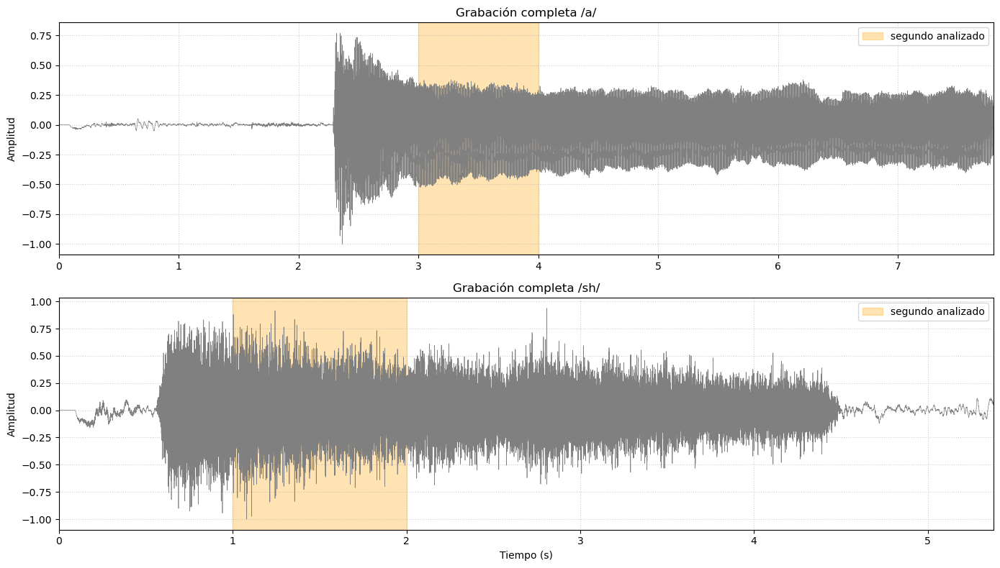

In [24]:
archivos = {"/a/": DIR_GRABACIONES / "a_16k.wav",
            "/sh/": DIR_GRABACIONES / "sh_16k.wav"}

# segundo (en s) donde empieza el tramo de 1 s elegido para cada sonido
inicios = {"/a/": 3.0, "/sh/": 1.0}

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (nombre, archivo) in zip(axes, archivos.items()):
    x_completo = cargar_audio(archivo, duracion=None)
    t = np.arange(len(x_completo)) / fs
    ax.plot(t, x_completo, color="gray", lw=0.5)
    ax.axvspan(inicios[nombre], inicios[nombre] + 1, color="orange", alpha=0.3, label="segundo analizado")
    ax.set_title(f"Grabación completa {nombre}")
    ax.set_ylabel("Amplitud")
    ax.set_xlim(0, t[-1])
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

In [27]:
# CARGAR EL SEGUNDO ELEGIDO DE /a/ Y /sh/ 
a = cargar_audio(archivos["/a/"], inicio=inicios["/a/"])
sh = cargar_audio(archivos["/sh/"], inicio=inicios["/sh/"])


# Para escuchar los tramos que se van a analizar
for nombre, x in [("/a/", a), ("/sh/", sh)]:
    print(f"{nombre} (1 s):")
    ipd.display(ipd.Audio(x, rate=fs))

/a/ (1 s):


/sh/ (1 s):


# Parte 2 (Predicción forward y MSE mínimo $J(M)$)

En este apartado se utiliza la predicción lineal forward. La idea es que, en lugar de mirar la señal completa, intentamos predecir cada muestra actual $x[n]$ a partir de las muestras inmediatamente anteriores. Si usamos un predictor de orden $M$, utilizamos las $M$ muestras anteriores para construir la predicción.

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

Aquí $x[n]$ es la muestra real, $\hat{x}[n]$ es la muestra predicha, $M$ indica cuántas muestras pasadas utilizamos y $a_1, a_2, \dots, a_M$ son los coeficientes del predictor.

Por ejemplo, para $M = 2$ sólo usamos $x[n-1]$ y $x[n-2]$; para $M = 20$ usamos las veinte muestras anteriores.

Los coeficientes $a_1, a_2, \dots, a_M$ no se eligen a mano. Se calculan a partir de la propia señal para que el error de predicción sea lo más pequeño posible. Para ello el código estudia cuánto se parece la señal a versiones retrasadas de sí misma mediante la autocorrelación.

La autocorrelación $r_x[k]$ mide, de forma simplificada, cuánto se parece $x[n]$ a $x[n-k]$. Por ejemplo, $r_x[1]$ mide la relación con la muestra anterior, $r_x[10]$ con una muestra situada diez posiciones atrás, etc. Esta información es la que permite determinar qué peso debe tener cada muestra pasada en la predicción.

A partir de estas correlaciones se construye el sistema de ecuaciones $\mathbf{R}\,\mathbf{a} = \mathbf{p}$. El vector $\mathbf{a}$ contiene los coeficientes $[a_1, a_2, \dots, a_M]^T$. Resolver este sistema proporciona los coeficientes óptimos, es decir, los que minimizan el error cuadrático medio para ese valor de $M$.

Una vez obtenida la predicción, se calcula el error forward como la diferencia entre la muestra real y la predicha:

$$e_f[n] = x[n] - \hat{x}[n]$$

Si el predictor acierta, $\hat{x}[n]$ será muy parecida a $x[n]$ y $e_f[n]$ será pequeño. Para resumir el error de toda la señal en un único número se calcula el error cuadrático medio (MSE), que en el enunciado se denomina $J(M)$:

$$J(M) = \frac{1}{N} \sum_n e_f^2[n]$$

Con los coeficientes óptimos este mínimo se puede calcular directamente a partir de la autocorrelación, sin tener que filtrar la señal:

$$J(M) = r_x[0] - \mathbf{p}^T \mathbf{a}$$

Por tanto, para cada valor de $M$ el procedimiento es siempre el mismo:

Se calcula la autocorrelación de la señal, se obtienen los coeficientes óptimos $a_1, \dots, a_M$, se forma la predicción $\hat{x}[n]$, se obtiene el error $e_f[n]$ y finalmente se calcula $J(M)$.

Después se repite todo el proceso para $M = 1, 2, 3, \dots$ y se representa $J$ frente a $M$.

## Qué hace el código con los audios antes de calcular $J(M)$

1. Lee el archivo WAV y obtiene la frecuencia de muestreo y las muestras $x[n]$.
2. Si el archivo tiene dos canales, se pasa a mono, ya que para este análisis sólo se necesita una señal.
3. Si la grabación no está a 16 kHz, se remuestrea a $f_s = 16$ kHz, tal como exige el enunciado.
4. Se selecciona un segundo de señal. A 16 kHz esto corresponde a 16 000 muestras.
5. Se elimina la media y se normaliza la amplitud. Esto centra la señal alrededor de cero y evita que diferencias de escala entre grabaciones afecten a la comparación.
6. Con la señal ya preparada se calcula la autocorrelación $r_x[k]$. A partir de ella se construyen $\mathbf{R}$ y $\mathbf{p}$ y se resuelve $\mathbf{R}\,\mathbf{a} = \mathbf{p}$ para obtener los coeficientes del predictor.
7. Finalmente se calcula el MSE mínimo $J(M)$. El código repite este cálculo para muchos valores de $M$, por lo que al final obtenemos una curva $J(M)$.

En general, al aumentar $M$ el predictor dispone de más información del pasado y $J(M)$ disminuye. Sin embargo, llega un momento en el que añadir más muestras anteriores apenas mejora la predicción. Esa transición es la que se observa mediante los llamados codos de la curva.

## Qué significa un "codo"

Un codo es una zona donde cambia claramente la pendiente de $J(M)$. Antes del codo, aumentar $M$ reduce bastante el error. Después del codo, el beneficio de seguir aumentando $M$ es mucho menor. El codo indica que el predictor acaba de capturar una estructura importante de la señal.

In [7]:
# FUNCIÓN PARA CALCULAR J(M)

def calcular_J(x, Mmax):

    N = len(x)

    # Autocorrelación
    r = correlate( x, x, mode="full", method="fft")

    centro = N - 1

    r = r[centro:centro + Mmax + 1] / N
    valores_J = []


    for M in range(1, Mmax + 1):
        p = r[1:M+1]
        a = solve_toeplitz((r[:M], r[:M]),p)

        # MSE mínimo
        J = r[0] - np.dot(p, a)

        valores_J.append(J)


    return np.array(valores_J)

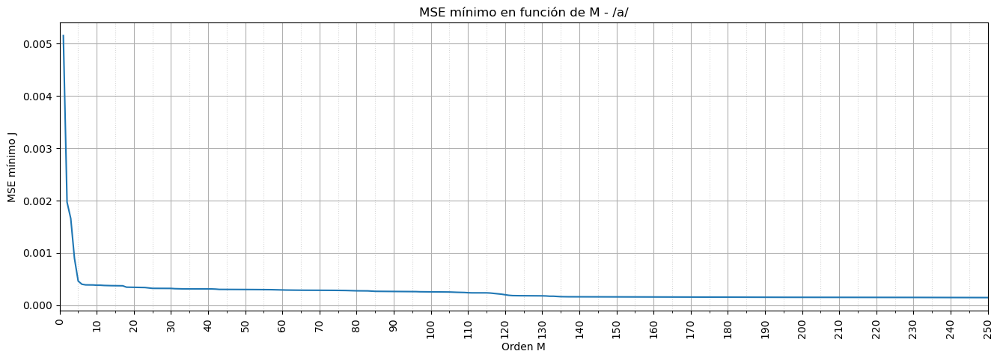

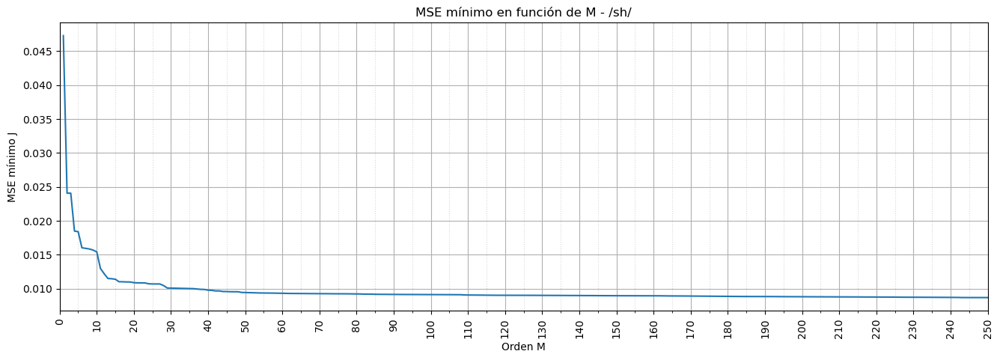

In [8]:
# CALCULAR J(M)
Mmax = 250

J_a = calcular_J(a,Mmax)
J_sh = calcular_J(sh,Mmax)

ordenes = np.arange( 1, Mmax + 1)

# GRÁFICA /a/
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(ordenes,J_a)
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE mínimo J")
ax.set_title( "MSE mínimo en función de M - /a/")
ax.set_xlim(0, Mmax)
ax.xaxis.set_major_locator(MultipleLocator(10))   # marca cada 10
ax.xaxis.set_minor_locator(MultipleLocator(5))    # marca menor cada 5
ax.grid(which="major")
ax.grid(which="minor", linestyle=":", alpha=0.5)
plt.xticks(rotation=90)
plt.show()

# GRÁFICA /sh/
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(ordenes, J_sh)
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE mínimo J")
ax.set_title("MSE mínimo en función de M - /sh/")
ax.set_xlim(0, Mmax)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(5))
ax.grid(which="major")
ax.grid(which="minor", linestyle=":", alpha=0.5)
plt.xticks(rotation=90)
plt.show()

## Graficando $J(M)$ en dB para poder ver los dos codos

En el gráfico anterior no se pueden ver los dos codos de /a/, debido a que el gráfico está dominado por la primera caída, y como el segundo "codo" tiene una reducción de error mucho más pequeña no se puede ver. Entonces graficamos el error de /a/ pero esta vez en dB para poder ver los dos codos más claramente. Ahora, en los gráficos nuevos se puede ver que el error para la grabación de /a/ claramente tiene otro codo alrededor de $M \approx 115$–$135$. En cambio, fijándose en el zoom de /sh/ se puede ver como no hay ningún otro codo, sino que el error simplemente decae.

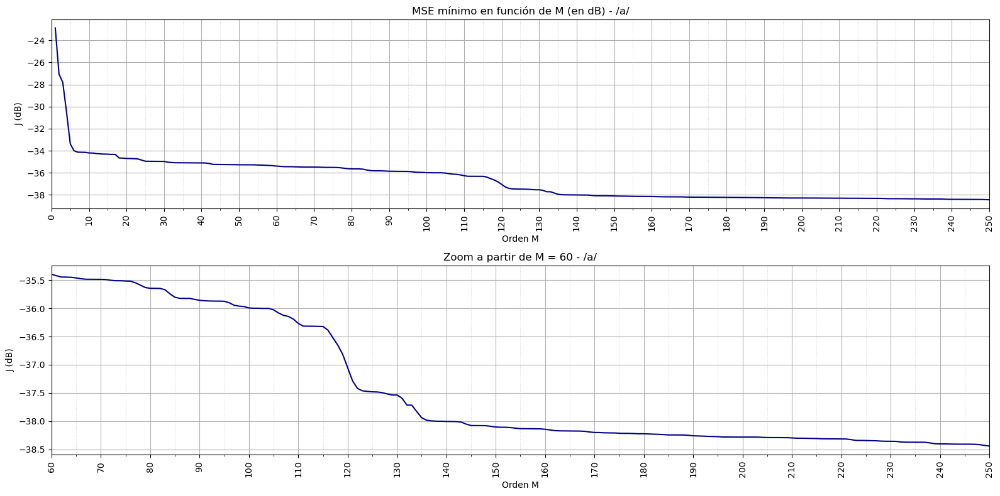

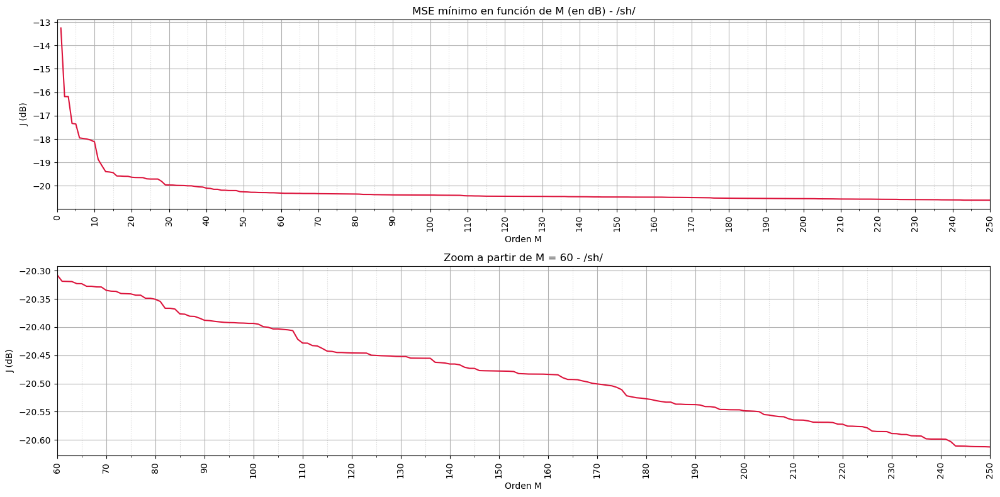

In [9]:
# J(M) EN dB PARA /a/ Y /sh/
J_a_dB = 10*np.log10(J_a)
J_sh_dB = 10*np.log10(J_sh)

def graficar_J_dB(M, J_dB, nombre, color, zoom_desde=60):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16,8))

    # Rango completo
    ax1.plot(M, J_dB, color=color)
    ax1.set_title(f"MSE mínimo en función de M (en dB) - {nombre}")
    ax1.set_ylabel("J (dB)")
    ax1.set_xlim(0, Mmax)

    # Zoom en la zona de M grandes (el eje y se ajusta solo a estos datos)
    zona = (M >= zoom_desde)
    ax2.plot(M[zona], J_dB[zona], color=color)
    ax2.set_title(f"Zoom a partir de M = {zoom_desde} - {nombre}")
    ax2.set_ylabel("J (dB)")
    ax2.set_xlim(zoom_desde, Mmax)

    for ax in (ax1, ax2):
        ax.set_xlabel("Orden M")
        ax.xaxis.set_major_locator(MultipleLocator(10))
        ax.xaxis.set_minor_locator(MultipleLocator(5))
        ax.grid(which="major")
        ax.grid(which="minor", linestyle=":", alpha=0.5)
        ax.tick_params(axis="x", rotation=90)

    plt.tight_layout()
    plt.show()

graficar_J_dB(ordenes, J_a_dB, "/a/", "navy")
graficar_J_dB(ordenes, J_sh_dB, "/sh/", "crimson")

## Investigando la señal de error $e_f(n)$

La primera parte es crear una función que calcule los coeficientes del predictor y el MSE mínimo (tomando como entrada una señal y el orden del filtro), y otra que con esos coeficientes genere la señal de error. Las dos se reutilizan en el resto del TP.

In [10]:
def calcular_predictor(x, M):
    N = len(x)

    # autocorrelación (lags 0..M)
    r = correlate(x, x, mode="full", method="fft")
    r = r[N-1:N+M] / N

    a = solve_toeplitz(r[:M], r[1:M+1])
    J = r[0] - np.dot(r[1:M+1], a)

    return a, J


def calcular_señal_de_error(x, M):

    a, _ = calcular_predictor(x, M)

    #creando la señal de error
    filtro_error = np.concatenate(([1], -a))
    e = lfilter(filtro_error, [1], x)

    return e

Ahora aplicamos esta función de error forward para calcular los errores de la señal /a/ y /sh/. Esto está hecho para intentar justificar por qué hay dos codos en vez de uno (como dice la recomendación en la consigna). Lo primero que hicimos es fijarnos en la señal de error en diferentes valores de $M$ para ver cómo la señal de error cambiaba dependiendo de si estábamos en el primer codo, en el segundo, etc. Para encontrar estos valores de $M$ nos fijamos en los gráficos que creamos anteriormente, donde utilizamos un python tool para que sean más precisos y se pueda leer mejor el valor de $M$.

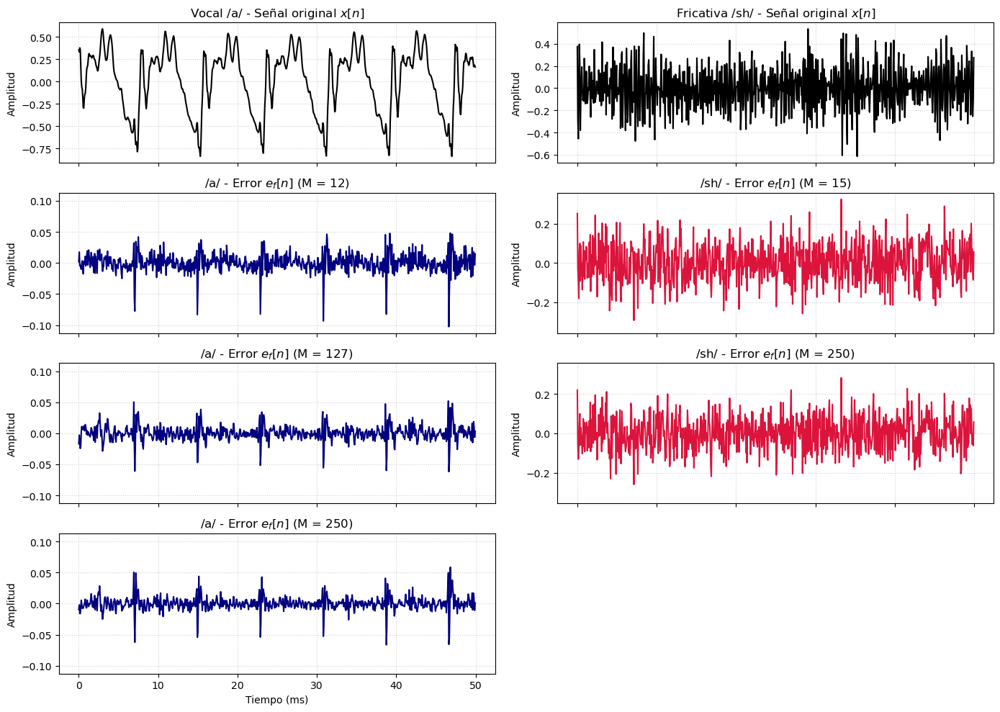

In [11]:
#estableciendo variables
inicio_tramo = 8000 # escogiendo un punto en el medio del segundo analizado
longitud = 800  # 50 ms
tiempo = np.arange(longitud) / fs * 1000 #ms

# Escogiendo diferentes M para el ruido /a/ para ver como cambia la señal de error dependiendo del codo
M_a_primer_codo = 12
M_a_segundo_codo = 127

# Lo mismo para /sh/
M_sh_primer_codo = 15

#ahora un M donde el error es mínimo para ambas señales
M_minimo = 250

tramo = slice(inicio_tramo, inicio_tramo + longitud)

# calculando la señal de error para /a/ con diferentes M (y recortando el tramo para graficar)
e_a_primer_codo = calcular_señal_de_error(a, M_a_primer_codo)[tramo]
e_a_segundo_codo = calcular_señal_de_error(a, M_a_segundo_codo)[tramo]
e_a_minimo = calcular_señal_de_error(a, M_minimo)[tramo]

# ahora haciendo lo mismo con la señal /sh/
e_sh_primer_codo = calcular_señal_de_error(sh, M_sh_primer_codo)[tramo]
e_sh_minimo = calcular_señal_de_error(sh, M_minimo)[tramo]

#escogiendo el tramo de audio para graficar
a_tramo = a[tramo]
sh_tramo = sh[tramo]

# graficando todo
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

# Columna de /a/
errores_a = [(M_a_primer_codo, e_a_primer_codo),
             (M_a_segundo_codo, e_a_segundo_codo),
             (M_minimo, e_a_minimo)]

axes[0, 0].plot(tiempo, a_tramo, color="black")
axes[0, 0].set_title("Vocal /a/ - Señal original $x[n]$")

for i, (M_i, e) in enumerate(errores_a):
    axes[i + 1, 0].plot(tiempo, e, color="navy")
    axes[i + 1, 0].set_title(f"/a/ - Error $e_f[n]$ (M = {M_i})")

# Columna de /sh/
errores_sh = [(M_sh_primer_codo, e_sh_primer_codo),
              (M_minimo, e_sh_minimo)]

axes[0, 1].plot(tiempo, sh_tramo, color="black")
axes[0, 1].set_title("Fricativa /sh/ - Señal original $x[n]$")

for i, (M_i, e) in enumerate(errores_sh):
    axes[i + 1, 1].plot(tiempo, e, color="crimson")
    axes[i + 1, 1].set_title(f"/sh/ - Error $e_f[n]$ (M = {M_i})")

# Mismo rango vertical para los errores de cada columna (así se compara la amplitud)
for col, errores in enumerate([errores_a, errores_sh]):
    ymax = max(np.max(np.abs(e)) for _, e in errores)
    for fila in range(1, 4):
        axes[fila, col].set_ylim(-1.1 * ymax, 1.1 * ymax)

for ax in axes.flatten():
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.set_ylabel("Amplitud")

axes[-1, 0].set_xlabel("Tiempo (ms)")
axes[-1, 1].set_xlabel("Tiempo (ms)")

axes[3, 1].axis("off")

plt.tight_layout()
plt.show()

Ahora graficamos la autocorrelación de la señal de error de /a/ (con $M = 12$) para ver si hay alguna correlación en lags más altos que el filtro no puede aprovechar cuando su orden es muy bajo. El lag del pico más alto (sin contar el lag 0) es el período de pitch $N_0$, que guardamos para usarlo en el punto 4.

N0 ≈ 128 muestras = 8.00 ms  ->  f0 ≈ 125.0 Hz


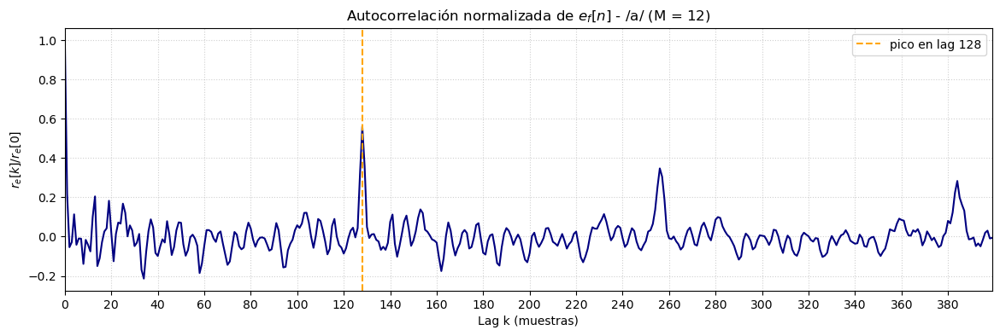

In [12]:
# graficando la autocorrelación de la señal de error para /a/ con M = 12

e = calcular_señal_de_error(a, M_a_primer_codo)[M_a_primer_codo:]     # sin el transitorio
e = e - np.mean(e)
r_e = correlate(e, e, mode="full", method="fft")
r_e = r_e[len(e)-1 : len(e)-1+400]
r_e = r_e / r_e[0]

# buscando el pico fuera de los primeros lags -> período de pitch
lag_min, lag_max = 60, 250   # equivale a buscar f0 entre 64 y 267 Hz
n0_estimado = lag_min + np.argmax(r_e[lag_min:lag_max])
print(f"N0 ≈ {n0_estimado} muestras = {1000 * n0_estimado / fs:.2f} ms  ->  f0 ≈ {fs / n0_estimado:.1f} Hz")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(r_e, color="navy")
ax.axvline(n0_estimado, color="orange", linestyle="--", label=f"pico en lag {n0_estimado}")
ax.set_title("Autocorrelación normalizada de $e_f[n]$ - /a/ (M = 12)")
ax.set_xlabel("Lag k (muestras)")
ax.set_ylabel("$r_e[k] / r_e[0]$")
ax.set_xlim(0, len(r_e) - 1)
ax.xaxis.set_major_locator(MultipleLocator(20))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.show()

## Interpretación de los resultados

Primero de todo se puede ver que la señal de error tiene energía en los mismos lugares en que la señal original tiene más energía (los picos de cada ciclo). Esto tiene todo el sentido del mundo, ya que los tramos donde la señal tiene más energía es donde el filtro se puede equivocar más, entonces el error también es más grande. Igualmente es interesante notarlo, como mínimo para asegurar que la función que calcula el error genera resultados esperados.

Para /a/ se observan dos cambios de pendiente. El primero aparece para órdenes bajos: la caída fuerte termina alrededor de $M \approx 6$ y a partir de $M \approx 12$ la curva ya es prácticamente plana (con un último escalón chico cerca de $M \approx 18$). Este primer codo está asociado a la correlación de corto plazo de la voz: con unos pocos coeficientes el predictor empieza a modelar la forma espectral introducida por el tracto vocal y sus resonancias (formantes). Cada formante es una resonancia que necesita un par de polos complejos conjugados, y en $0$–$8$ kHz hay unos 4–5 formantes, así que hacen falta del orden de $2 \cdot 5 + 2 \approx 12$ coeficientes (los 2 extra para la inclinación espectral de la glotis y la radiación de los labios). Los formantes más fuertes (F1 y F2, en bajas frecuencias, donde está casi toda la energía) se capturan con muy pocos coeficientes, por eso la caída grande termina tan pronto; los formantes más débiles de alta frecuencia solo agregan mejoras chicas hasta $M \approx 12$–$18$.

Fijándonos en la señal de error para este valor de $M$ se puede ver cómo es un tren de pulsos separado por unos 8 ms. También se puede notar cómo la magnitud de estos pulsos es bastante alta y además hay mucha variación notable entre los pulsos, entonces sigue habiendo mucho error.

Más adelante aparece un segundo cambio, aproximadamente alrededor de $M \approx 115$–$135$. La vocal /a/ es periódica, por lo que una muestra se parece a otra situada aproximadamente un periodo de pitch antes. Cuando $M$ alcanza ese retardo, el predictor puede aprovechar esa periodicidad y el MSE vuelve a reducirse de forma leve pero visible en dB. Entre los dos codos (para $20 \lesssim M < N_0$) la curva es casi plana: agregar coeficientes no sirve de nada porque el pulso anterior todavía está fuera de la "memoria" del predictor.

La señal de error para este valor de $M$ refleja esto, ya que los pulsos que se podían ver anteriormente tienen una magnitud más pequeña (los picos negativos bajan de $\approx 0{,}09$ a $\approx 0{,}06$), y también el ruido entre los pulsos se redujo. Igual los pulsos no desaparecen del todo: el período no es perfectamente constante (ver jitter en el punto 4), así que el ciclo anterior no predice exactamente al actual.

Esto se puede ver claramente en la señal de autocorrelación graficada justo antes de esta sección (para $M = 12$). Se puede ver cómo hay un pico cuando el lag tiene un valor de 128 (también se pueden ver los armónicos, en 256 y 384), que es exactamente donde el segundo codo ocurre. Esta vocal es periódica, entonces tiene autocorrelación que el filtro puede utilizar, pero solo si el orden del filtro es suficientemente grande. Entonces cuando el orden del filtro aumenta para poder incluir toda la autocorrelación presente en lags anteriores, ahí es cuando el error se puede reducir de vuelta, y a su vez cuando la función de error tiene el segundo codo. (El escalón está repartido entre $\approx 115$ y $\approx 135$ porque el pico de autocorrelación tiene cierto ancho: el período varía levemente de ciclo a ciclo y el pulso dura varias muestras.)

$$N_0 \approx \frac{f_s}{f_0}$$

Si el segundo codo se sitúa cerca de $M \approx 128$ y $f_s = 16\,000$ Hz, la frecuencia fundamental asociada sería aproximadamente $f_0 \approx 16\,000/128 = 125$ Hz, un valor razonable para una voz sostenida.

Wikipedia (https://en.wikipedia.org/wiki/Voice_frequency) dice que "the voiced speech of a typical adult male will have a fundamental frequency from 90 to 155 Hz", y nuestra grabación es de un hombre, entonces tiene todo el sentido del mundo. No nos fiamos de Wikipedia por completo, entonces averiguamos un poco más y un artículo de la Biblioteca Nacional de Medicina del gobierno americano (https://pmc.ncbi.nlm.nih.gov/articles/PMC8478519/) dice que los hombres tienen un rango de "78 to 182 Hz", que también justifica el valor que calculamos.

Para /sh/ se observa principalmente un único codo en órdenes bajos (la curva cae hasta $M \approx 12$–$15$, con algún escalón chico hasta $M \approx 30$, y después es casi plana). Esto concuerda con que /sh/ es un sonido no sonoro: no existe una vibración periódica clara de las cuerdas vocales y, por tanto, no aparece un segundo codo asociado a un periodo de pitch.

También fijándonos en la señal de error se puede ver cómo no hay ningún tipo de pulsos ni nada, se parece bastante al ruido. Entonces no hay ningún tipo de periodicidad que explique esta señal y que a su vez pueda aprovechar el filtro para reducir el error.

# Parte 3 (Respuesta en frecuencia del filtro del error de predicción)

El tercer ejercicio utiliza los coeficientes obtenidos por el predictor, pero no pide representar el predictor directamente. Pide representar el filtro que genera el error de predicción.

## Predictor frente a filtro del error

El predictor calcula una estimación de $x[n]$:

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

Como $e_f[n] = x[n] - \hat{x}[n]$, podemos escribir:

$$e_f[n] = x[n] - a_1 x[n-1] - a_2 x[n-2] - \cdots - a_M x[n-M]$$

Esto equivale a pasar $x[n]$ por un filtro FIR cuyos coeficientes son:

$$\bar{\mathbf{a}} = [1,\ -a_1,\ -a_2,\ \dots,\ -a_M]$$

Éste es el filtro del error de predicción. Su función es eliminar de la voz aquello que el predictor considera predecible. Por eso su salida es precisamente $e_f[n]$.

$$x[n] \;\longrightarrow\; \boxed{A(z)} \;\longrightarrow\; e_f[n]$$

## Por qué se representa $H(e^{j\omega})$

La respuesta en frecuencia indica qué frecuencias atenúa o deja pasar el filtro del error. Si la voz tiene una resonancia fuerte y muy predecible en cierta zona, el filtro tiende a crear un valle alrededor de esa frecuencia para eliminarla del residual. El objetivo ideal es que el error conserve poca estructura y se parezca más a ruido.

El ejercicio pide repetir este cálculo para $M = 1, 2, 4, 8, 16, 32$ y $64$. Así se ve cómo aumenta la capacidad del filtro para modelar la señal a medida que aumenta su orden.

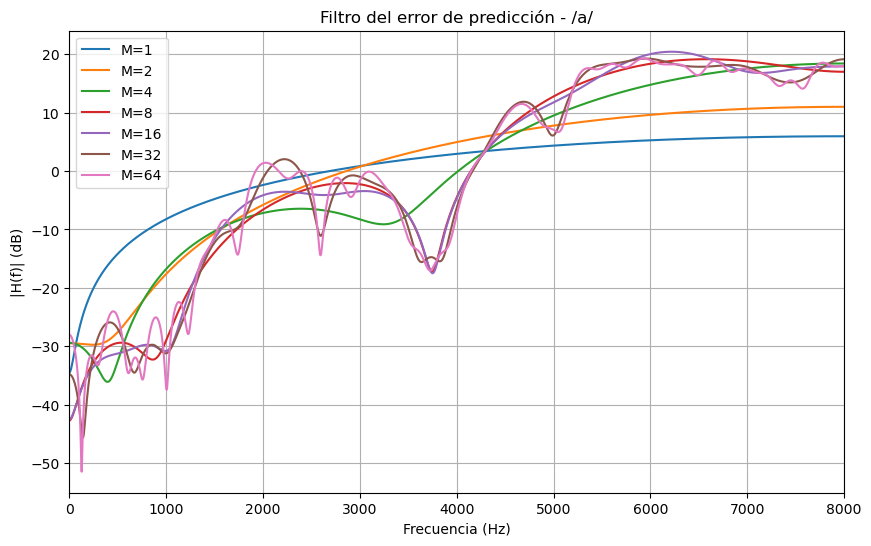

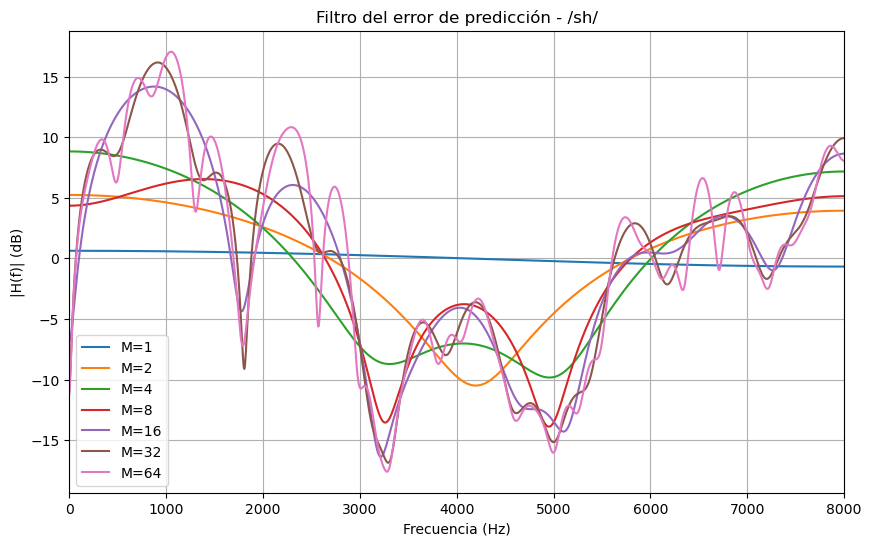

In [28]:
# VALORES DE M
valores_M = [1, 2, 4, 8, 16, 32, 64]

señales = {"/a/": a, "/sh/": sh}

for nombre, x in señales.items():

    plt.figure(figsize=(10,6))

    for M in valores_M:

        coef, _ = calcular_predictor(x, M)

        # FILTRO DEL ERROR
        filtro_error = np.concatenate(([1], -coef))

        f, H = freqz(filtro_error,worN=2048,fs=fs)

        plt.plot( f,20*np.log10(np.abs(H) + 1e-12),label=f"M={M}")

    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("|H(f)| (dB)")
    plt.title(f"Filtro del error de predicción - {nombre}")
    plt.xlim(0, fs/2)
    plt.legend()
    plt.grid()
    plt.show()

## Interpretación de las curvas

Para órdenes muy bajos, como $M = 1$ o $M = 2$, el filtro sólo puede describir una tendencia espectral muy simple. Las curvas son suaves porque hay pocos coeficientes disponibles.

Al pasar a $M = 4, 8, 16, 32$ y $64$ aparecen valles y variaciones más definidos. Esto significa que el filtro está aprendiendo más detalles de la estructura espectral de cada fonema y eliminando de la salida aquellas componentes que son más predecibles.

En /a/, que es un sonido sonoro, la respuesta se vuelve progresivamente más detallada porque existe una estructura espectral y temporal importante. En /sh/ también se modela su coloración espectral, pero no aparece una periodicidad de pitch tan marcada, ya que es un sonido no sonoro.

La relación con $J(M)$ es directa: mientras aumentar $M$ produce una caída apreciable de $J$, el nuevo orden está explicando estructura adicional. Cuando $J(M)$ empieza a aplanarse, aumentar el orden modifica detalles cada vez más finos de $H(e^{j\omega})$ pero aporta una mejora pequeña en el error total.

### Lo que se ve en nuestras curvas  [editar esto, combinar con interpretaction! No usar informacion que no se ve de los graficos, usar los codos en la argumentacion]

**$M = 1$.** Para /a/  el filtro es un pasa-altos fuerte: $|H|$ va de unos $-35$ dB en continua a $+6$ dB en 8 kHz. Con $M = 1$ el único coeficiente es $a_1 = r_x[1]/r_x[0] \approx 0{,}98$, porque en una vocal dos muestras consecutivas son casi iguales (la energía está en bajas frecuencias), y entonces $e_f[n] = x[n] - 0{,}98\,x[n-1]$ es prácticamente una derivada. Para /sh/, en cambio, la curva con $M = 1$ es casi plana (menos de 1 dB de variación): $a_1 \approx -0{,}07$, es decir, dos muestras consecutivas de /sh/ casi no están correlacionadas, y por eso en el punto 2 $J(1)$ es prácticamente igual a $r_x[0]$.

**Los valles son los formantes.** El filtro del error es (a menos de la ganancia $J$) la inversa de la envolvente espectral de la señal: pone valles exactamente donde la señal tiene sus resonancias, para sacarlas del error. En la figura de espectros se ve que $J/|H|^2$ sigue la envolvente de $S_x(f)$ cada vez mejor al aumentar $M$. En /a/ los valles están en la zona de bajas frecuencias ($< 1{,}2$ kHz, donde están F1 y F2) y alrededor de $2{,}6$ kHz y $3{,}75$ kHz (F3 y F4). En /y/ los valles se corren (F1 muy bajo y F2 cerca de 2 kHz), que es lo que distingue una vocal de otra. En /sh/ los valles están en $\approx 3{,}3$ kHz y $\approx 5$ kHz, que es donde se concentra la energía de la fricativa (el ruido turbulento que se genera en la constricción solo resuena en la cavidad chica delante de ella, por eso es de alta frecuencia), y el filtro *amplifica* alrededor de 1 kHz y arriba de 7 kHz, donde /sh/ casi no tiene energía.

**Rango dinámico y $J(M)$.** El filtro de /a/ tiene un rango de unos 70 dB y el de /sh/ solo unos 35 dB. Es coherente con el punto 2: la ganancia de predicción $r_x[0]/J(M)$ es de unos 30 dB para /a/ ($-8{,}6$ dB $\to -38{,}4$ dB) y de apenas 7 dB para /sh/ ($-13{,}2$ dB $\to -20{,}6$ dB). Cuanto más "coloreado" está el espectro, más predecible es la señal y más tiene que trabajar el filtro para blanquearla.

**$M = 16$ frente a $M = 64$ y el pitch.** A partir de $M \approx 8$–$16$ los valles principales ya no se mueven: la envolvente está capturada, que es justo el final del primer codo de $J(M)$. Pasar a 32 o 64 solo agrega ondulaciones angostas. En /a/, para $M = 64$ esas ondulaciones en baja frecuencia empiezan a seguir los armónicos individuales, pero no llegan a resolverlos: un FIR de orden $M$ solo puede generar detalles de un ancho del orden de $f_s/M$, y para poner un valle en cada armónico (separados $f_0 \approx 125$ Hz) hace falta

$$\frac{f_s}{M} \lesssim f_0 \quad\Longrightarrow\quad M \gtrsim \frac{f_s}{f_0} = N_0 \approx 128,$$

que es exactamente la condición del segundo codo de $J(M)$, vista desde la frecuencia. Por eso con $M \le 64$ el error queda "blanqueado" solo en la envolvente: en el zoom se ve que $S_e(f)$ tiene todos los armónicos más o menos a la misma altura (envolvente plana), pero sigue siendo un peine de rayas en múltiplos de $f_0$. Un peine de rayas en frecuencia es un tren de pulsos en el tiempo, que es justamente el $e_f[n]$ que vimos en el punto 2. Para /sh/, en cambio, $S_e(f)$ queda prácticamente plano: el error es ruido blanco, lo que justifica el modelo de excitación del punto 4.

# Parte 4 (Comparando grabación real con grabación simulada)

Las funciones `calcular_predictor` (coeficientes y MSE mínimo, tomando la señal y el orden como entrada) y `calcular_señal_de_error` ya se definieron en el punto 2, así que las reutilizamos acá.

[eliminar esta redundancia]
Cargamos los audios de vuelta, para asegurar que los audios que estamos analizando aquí no han sido cambiados. En teoría no tendría que haber cambiado nada, pero igualmente está bien incluirlo aquí al lado para no tener que preocuparnos de que estas variables cambiaron anteriormente y tener que fijarnos en todo el código.

In [15]:
# CARGAR /a/ Y /sh/ (el mismo segundo que en la parte 1)
a = cargar_audio(archivos["/a/"], inicio=inicios["/a/"])
sh = cargar_audio(archivos["/sh/"], inicio=inicios["/sh/"])

## Explicación del código

Primero de todo hay valores de $M$ diferentes dependiendo de la señal que estemos analizando. La consigna pide utilizar un valor de $M$ donde termine el primer codo. Estos valores ya se encontraron en el punto 2, donde analizamos el error como función de $M$ y encontramos los valores de $M$ para los codos de /a/ ($M = 12$) y /sh/ ($M = 15$).

Después, para escoger la excitación para usar nos podemos fijar en las señales de error que se graficaron en el punto 2.

Como se puede ver, el error para la señal /a/ es un tren de impulsos con un período de alrededor de 128 muestras (esto también se discutió en el punto 2, y es el `n0_estimado` que sacamos de la autocorrelación del error). Los pulsos del error real son negativos (corresponden al cierre de la glotis), así que usamos impulsos negativos. Para el oído la polaridad no cambia nada, pero así la forma de onda sintetizada se puede comparar directamente con la original. También se tiene que definir la amplitud de cada impulso. Hay que asegurar que la energía por muestra sea $J$, y como hay un impulso cada $N_0$ muestras y cada uno aporta $g^2$:

$$\frac{g^2}{N_0} = J$$

Entonces:

$$g = \sqrt{J \cdot N_0}$$

En cambio la señal de error para el /sh/ es básicamente ruido (fijarse en el gráfico del punto 2), entonces se puede modelar como ruido blanco gaussiano escalado para que su varianza sea $J$.

Después de esto el código simplemente utiliza la inversa del filtro, $1/A(z)$, para producir la señal desde las excitaciones artificiales que creamos en el código.

In [16]:
# definiendo variables
M_a = 12
M_sh = 15
n0 = n0_estimado  # período de pitch del punto 2 (128 muestras)
print("n0 =", n0)

N_a = len(a)
N_sh = len(sh)
rng = np.random.default_rng(0)  # semilla fija para que los resultados se puedan repetir

# Calculando los coeficientes del predictor y el MSE mínimo J para /a/ y /sh/
a_coef, J_a_pred = calcular_predictor(a, M_a)
sh_coef, J_sh_pred = calcular_predictor(sh, M_sh)

g = np.sqrt(J_a_pred * n0)
h = np.sqrt(J_sh_pred)

#creando las señales de excitacion
a_exc = np.zeros(N_a)
a_exc[::n0] = -g  # un impulso de amplitud g cada n0 muestras (negativo, como los pulsos del error real)
sh_exc = rng.standard_normal(N_sh) * h

# chequeo: la energía por muestra de la excitación tiene que ser parecida a J
print(np.mean(a_exc**2), J_a_pred)
print(np.mean(sh_exc**2), J_sh_pred)

#ahora utilizando los coeficientes del predictor en inversa para producir la señal sintetizada
a_sint = lfilter([1], np.concatenate(([1], -a_coef)), a_exc)
sh_sint = lfilter([1], np.concatenate(([1], -sh_coef)), sh_exc)

# chequeo: la potencia de la señal sintetizada tiene que ser parecida a la original
print(np.mean(a_sint**2), np.mean(a**2))
print(np.mean(sh_sint**2), np.mean(sh**2))

# guardando los audios (normalizados para que no haya clipping)
def guardar_audio(nombre, y):
    y = y / np.max(np.abs(y))
    wavfile.write(DIR_SINTETIZADAS / nombre, fs, (y * 32767).astype(np.int16))

guardar_audio("a_sintetizada.wav", a_sint)
guardar_audio("sh_sintetizada.wav", sh_sint)

# escuchando original vs sintetizada
for nombre, original, sintetizada in [("/a/", a, a_sint), ("/sh/", sh, sh_sint)]:
    print(f"{nombre} original:")
    ipd.display(ipd.Audio(original, rate=fs))
    print(f"{nombre} sintetizada:")
    ipd.display(ipd.Audio(sintetizada, rate=fs))

n0 = 128
0.00037479955385985586 0.00037479955385985586
0.011326877530655389 0.011387731867193544
0.13816069587597915 0.13821795588261768
0.0457301896830712 0.04754316873672324
/a/ original:


/a/ sintetizada:


/sh/ original:


/sh/ sintetizada:


Para poder comparar no solo escuchando, graficamos la excitación real (el error $e_f[n]$) contra la excitación del modelo, y la señal original contra la sintetizada, en tiempo y en frecuencia.

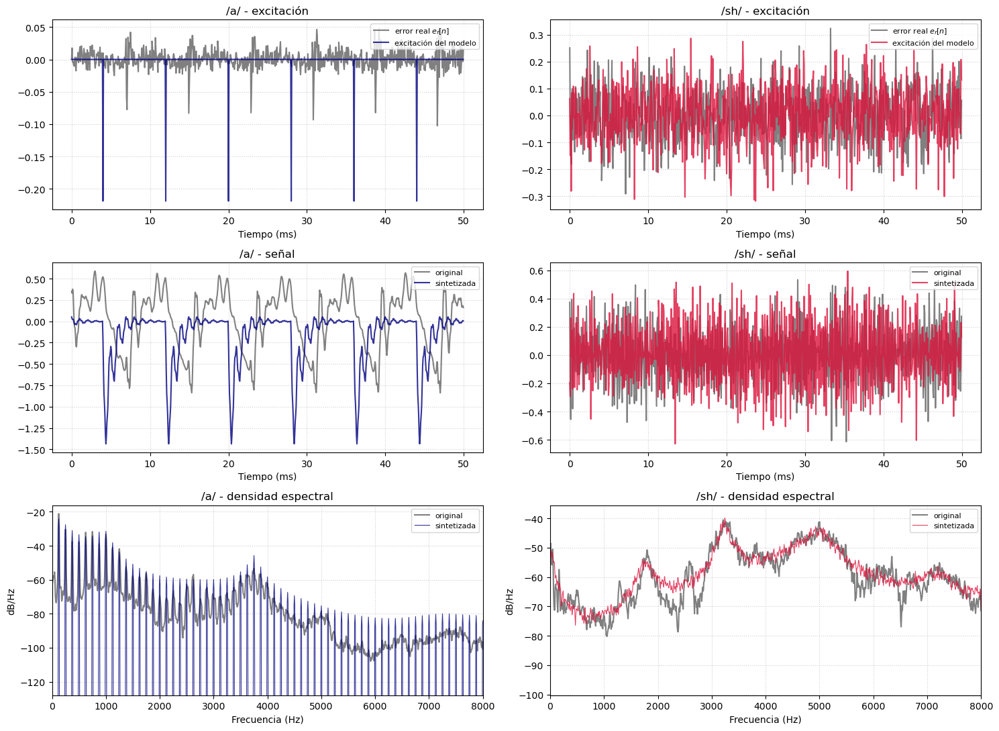

In [17]:
e_a_real = calcular_señal_de_error(a, M_a)
e_sh_real = calcular_señal_de_error(sh, M_sh)

fig, axes = plt.subplots(3, 2, figsize=(15, 11))

for col, (nombre, x, x_sint, e_real, exc, color) in enumerate([
        ("/a/", a, a_sint, e_a_real, a_exc, "navy"),
        ("/sh/", sh, sh_sint, e_sh_real, sh_exc, "crimson")]):

    # excitación real vs modelo
    ax = axes[0, col]
    ax.plot(tiempo, e_real[tramo], color="gray", label="error real $e_f[n]$")
    ax.plot(tiempo, exc[tramo], color=color, alpha=0.8, label="excitación del modelo")
    ax.set_title(f"{nombre} - excitación")
    ax.set_xlabel("Tiempo (ms)")

    # señal original vs sintetizada
    ax = axes[1, col]
    ax.plot(tiempo, x[tramo], color="gray", label="original")
    ax.plot(tiempo, x_sint[tramo], color=color, alpha=0.8, label="sintetizada")
    ax.set_title(f"{nombre} - señal")
    ax.set_xlabel("Tiempo (ms)")

    # espectros
    ax = axes[2, col]
    f, P = welch(x, fs=fs, nperseg=2048)
    f, P_sint = welch(x_sint, fs=fs, nperseg=2048)
    ax.plot(f, 10*np.log10(P), color="gray", label="original")
    ax.plot(f, 10*np.log10(P_sint), color=color, alpha=0.8, lw=0.8, label="sintetizada")
    ax.set_xlim(0, fs/2)
    # la sintetizada de /a/ tiene rayas perfectas y casi nada entre ellas, limitamos el eje y
    ax.set_ylim(10*np.log10(P).min() - 20, 10*np.log10(P).max() + 5)
    ax.set_title(f"{nombre} - densidad espectral")
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("dB/Hz")

for ax in axes.flatten():
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## Discusión de Resultados

Comparando la grabación generada y la grabación real de /a/ se puede escuchar cómo la versión sintetizada es muy robótica comparada a la grabación original. Esto es debido a que literalmente solo consideramos los impulsos, y no el ruido que también hay entre impulsos y todas las otras imperfecciones de la grabación, entonces toda la parte "natural" de la grabación desaparece y solo notamos la información del tracto vocal de la /a/.

Específicamente se perdieron varias cosas cuando creamos nuestra propia excitación y no utilizamos el error exacto.

Primero de todo, estuvimos averiguando y aparentemente la voz humana tiene jitter, que significa que el período cambia levemente entre ciclos (https://speechprocessingbook.aalto.fi/representations/jitter-and-shimmer). En cambio, la voz que generamos nosotros con el filtro inverso no tiene nada de esto, ya que utilizamos un período constante durante toda la realización.

Otra característica del error creado por la voz humana es que los picos no tienen todos exactamente la misma amplitud, sino que van variando, y esto es conocido como shimmer (https://speechprocessingbook.aalto.fi/representations/jitter-and-shimmer).

Finalmente, también asumimos un modelo constante durante toda la duración de la grabación, y es imposible que un humano mantenga un mismo "tono" perfecto durante un tiempo prolongado.

Igualmente, es sorprendente lo similar que es esta versión sintetizada a una /a/, ya que claramente se puede identificar esta vocal. Esto también se ve en los espectros: la envolvente (los formantes) de la señal sintetizada coincide con la original, porque es justamente lo que modela $1/A(z)$ con $M = 12$, y los armónicos caen en los mismos múltiplos de $f_0$. Lo que cambia es la estructura fina: en la sintetizada los armónicos son líneas perfectas (período exactamente constante) y no hay ruido entre ellos.

En cambio, como el error de la señal de /sh/ era simplemente ruido blanco, la excitación del modelo es prácticamente indistinguible del error real (primer gráfico de la derecha), y la señal sintetizada es ruido con la misma coloración espectral que la original (el espectro de la sintetizada sigue al de la original casi exactamente). Para un sonido no sonoro el modelo "ruido blanco + $1/A(z)$" es casi exacto, por eso la /sh/ sintetizada se parece mucho más a la original que en el caso de la /a/. Lo único que se pierde son las pequeñas variaciones temporales de la fricativa real, ya que la excitación y el filtro son estacionarios durante todo el segundo.

## Modificando el modelo

Después de averiguar un poco más sobre la voz humana y aprender sobre conceptos como shimmer y jitter, intentamos generar un programa que medio randomice el período y las amplitudes del impulso (pero dentro de un cierto rango) para intentar crear una /a/ un poco más humana. También añadimos un poco de ruido entre pulsos, ya que como dijimos en la explicación anterior no son pulsos sino que también hay ruido aleatorio.

In [33]:
# definiendo variables
M_a = 12
n0 = n0_estimado

jitter = 0.02  # variación del período entre pulsos (desvío estándar, como fracción de n0)
shimmer = 0.2  # variación de la amplitud de cada pulso (desvío estándar, como fracción de g)
ruido_rel = 0.1  # fracción de la energía de la excitación que se le da al ruido

N_a = len(a)
rng = np.random.default_rng(0)  # semilla fija para que los resultados se puedan repetir

# Calculando los coeficientes del predictor y el MSE mínimo J para /a/
a_coef, J_a_pred = calcular_predictor(a, M_a)

g = np.sqrt(J_a_pred * (1 - ruido_rel) * n0)  # amplitud base de cada impulso

#creando la excitacion: impulsos con jitter y shimmer
impulsos = np.zeros(N_a)
pos = 0.0
while pos < N_a:
    impulsos[int(pos)] = -g * (1 + shimmer * rng.standard_normal())  # amplitud variable (negativo, como en el error real)
    pos += n0 * (1 + jitter * rng.standard_normal())  # período variable

# ajustando la energía de los impulsos para que coincida con la parte de J que les corresponde
impulsos *= np.sqrt(J_a_pred * (1 - ruido_rel) / np.mean(impulsos**2))

# ruido blanco gaussiano de fondo
ruido = rng.standard_normal(N_a) * np.sqrt(J_a_pred * ruido_rel)

a_exc_humana = impulsos + ruido

# chequeo: la energía por muestra de la excitación tiene que ser parecida a J
print(np.mean(a_exc_humana**2), J_a_pred)

#ahora utilizando los coeficientes del predictor en inversa para producir la señal sintetizada
a_sint_humana = lfilter([1], np.concatenate(([1], -a_coef)), a_exc_humana)

# chequeo: la potencia de la señal sintetizada tiene que ser parecida a la original
print(np.mean(a_sint_humana**2), np.mean(a**2))

# guardando el audio (usa la función guardar_audio de antes)
guardar_audio("a_sintetizada_humana.wav", a_sint_humana)

print("/a/ original:")
ipd.display(ipd.Audio(a, rate=fs))
print("/a/ sintetizada (período constante):")
ipd.display(ipd.Audio(a_sint, rate=fs))
print("/a/ sintetizada con jitter, shimmer y ruido:")
ipd.display(ipd.Audio(a_sint_humana, rate=fs))

0.0003750643798694736 0.00037479955385985586
0.13555274813249782 0.13821795588261768
/a/ original:


/a/ sintetizada (período constante):


/a/ sintetizada con jitter, shimmer y ruido:


Estuvimos probando diferentes valores de jitter, shimmer y ruido generado y realmente se puede escuchar una diferencia, ya que no suena tan robótica y desagradable la voz sintetizada. Igualmente, sigue sonando muy robótica y no tiene nada que ver con una voz humana real, ya que con un error hecho con funciones matemáticas relativamente simples es imposible capturar el error exacto para recrear la voz humana y que suene natural.

# Parte 5 (Grabación Sintetizada)

[demasiado texto aca, mucho mas corto]
Ahora se aplica la misma idea que en el punto 4 pero a una grabación larga de voz libre, donde el tracto vocal cambia todo el tiempo. Como la voz solo es aproximadamente estacionaria en tramos cortos, se trabaja por bloques:

1. Se divide la señal en bloques de $L = 50$ ms $= 800$ muestras, con un overlap del 50 % (cada bloque avanza `hop` $= 400$ muestras).
2. Cada bloque se multiplica por una ventana de Hann y se calculan los coeficientes del predictor forward con $M = 12$ (el primer codo: solo modela la envolvente / formantes, no el pitch).
3. El error de predicción de cada bloque se reemplaza por un tren de impulsos de $160$ Hz, o sea un impulso cada $P = f_s / 160 = 100$ muestras. El tren se crea una sola vez para toda la señal, antes del bucle, y cada bloque toma su pedazo; así los impulsos quedan en la misma posición absoluta en todos los bloques (coherente entre bloques) y al solaparse no aparecen impulsos corridos.
4. Se filtra la excitación de cada bloque con $1/A(z)$, se ventanea el resultado de nuevo con Hann, y se suman los bloques en su posición (overlap-add).

Usamos la ventana de Hann "periódica" (`windows.hann(L, sym=False)`): con overlap del 50 % la suma de las ventanas desplazadas da exactamente 1, así que el overlap-add no agrega modulaciones de amplitud.

In [19]:
# Cargando el audio de voz libre
grab_libre = cargar_audio(DIR_GRABACIONES / "long_rec_16k.wav", duracion=None)  # duracion=None para no limitar la duración

# Definiendo los parametros
fs = 16000
L = int(0.05 * fs)  # 50 ms -> 800 muestras
hop = L // 2  # cuanto avanza la ventana de bloque a bloque (overlap del 50 %)
M = 12
P = fs // 160  # Período (pero en samples no por segundos) -> 100 muestras
N = len(grab_libre)
cantidad_bloques = (N - L) // hop + 1 # Cantidad de bloques que entran en la señal de largo N

ventana = windows.hann(L, sym=False)

# chequeo: con 50 % de overlap las ventanas de Hann suman 1
suma_ventanas = np.zeros(N)
for i in range(cantidad_bloques):
    suma_ventanas[i * hop:i * hop + L] += ventana
print("Suma de ventanas (lejos de los bordes): min =", suma_ventanas[L:-L].min(), " max =", suma_ventanas[L:-L].max())

# creando el tren de impulsos fuera del bucle
tren_impulsos = np.zeros(N)
tren_impulsos[::P] = 1
voz_sint = np.zeros(N) # variable para señal sintetizada
picos_bloques = np.zeros(cantidad_bloques)  # pico de cada bloque sintetizado (para analizar después)
polo_max = np.zeros(cantidad_bloques)       # módulo del polo más cercano a la circunferencia unidad

# Trabajando bloque a bloque
for i in range(cantidad_bloques):
    bloque = grab_libre[i * hop:i * hop + L]
    bloque_modificado = bloque * ventana  # Aplicando ventana de Hann
    r = np.array([np.dot(bloque_modificado[:L-k], bloque_modificado[k:]) for k in range(M+1)]) # calcula la auto a mano (bastante ineficiente, pero para 12 lags funciona bien)
    if r[0] == 0:  # bloque de silencio digital: no hay nada que predecir
        continue
    coeficientes = solve_toeplitz(r[:M], r[1:M+1])

    # Filtrando el tren de impulsos con los coeficientes obtenidos
    filtro_error = np.concatenate(([1], -coeficientes))
    excitacion = tren_impulsos[i * hop:i * hop + L]
    bloque_sintetizado = lfilter([1], filtro_error, excitacion)
    bloque_sintetizado *= ventana
    voz_sint[i * hop:i * hop + L] += bloque_sintetizado

    picos_bloques[i] = np.max(np.abs(bloque_sintetizado))
    polo_max[i] = np.max(np.abs(np.roots(filtro_error)))

# Normalizando la señal sintetizada
voz_sint /= np.max(np.abs(voz_sint))

# Guardando la señal sintetizada
wavfile.write(DIR_SINTETIZADAS / "voz_sintetizada.wav", fs, (voz_sint * 32767).astype(np.int16))

print("Grabación original:")
ipd.display(ipd.Audio(grab_libre, rate=fs))
print("Voz sintetizada:")
ipd.display(ipd.Audio(voz_sint, rate=fs))

Suma de ventanas (lejos de los bordes): min = 0.9999999999999996  max = 1.0000000000000002
Grabación original:


Voz sintetizada:


## Comparación de la señal grabada con la señal sintetizada [impossible to know at this step as "Voz sintetizada is completly silent, the following structure and reasoning has to change accordingly, feel free to alter any code that follows after this markdown until the end of the document]

La diferencia más grande que notamos al principio es que la señal sintetizada tiene un volumen mucho más bajo que la señal. Esto es debido a tres razones diferentes:
1. **Los impulsos son muy picudos.** Normalizás por el pico máximo, y una señal excitada por impulsos tiene picos altos pero energía promedio (RMS) baja. Al dejar el pico en 1, el resto queda chico.
2. **La ganancia del filtro $1/A(z)$ cambia mucho de un bloque a otro.** Los bloques con resonancias fuertes (vocales) amplifican bastante, y los de silencio o ruido casi nada. Unos pocos bloques fijan el pico y el resto queda muy por debajo.
3. **Cada bloque recibe impulsos de amplitud 1**, sin importar si el original era fuerte o débil. La señal sintetizada pierde la información de nivel.

En nuestra grabación el punto 2 es extremo. Miramos qué bloques tienen el pico más alto antes de normalizar:

In [20]:
# ¿Qué bloques fijan el pico de la señal sintetizada?
for i in np.argsort(picos_bloques)[::-1][:4]:
    print(f"bloque {i:4d} (t = {i * hop / fs:6.3f} s): pico = {picos_bloques[i]:10.1f}   polo más cercano a |z|=1: {polo_max[i]:.5f}")
print(f"mediana de los picos de todos los bloques: {np.median(picos_bloques):.1f}")

# la grabación empieza con silencio digital (ceros), que después de quitar la media queda constante
inicio_constante = np.argmax(np.diff(grab_libre) != 0) + 1
print(f"las primeras {inicio_constante} muestras ({1000 * inicio_constante / fs:.0f} ms) son constantes")

# misma síntesis, pero renormalizada sin ese tramo inicial
voz_sint_sin_inicio = voz_sint.copy()
voz_sint_sin_inicio[:inicio_constante] = 0
voz_sint_sin_inicio /= np.max(np.abs(voz_sint_sin_inicio))
print("Voz sintetizada (impulsos de amplitud 1), renormalizada sin el tramo inicial:")
ipd.display(ipd.Audio(voz_sint_sin_inicio, rate=fs))

bloque    0 (t =  0.000 s): pico =   128935.4   polo más cercano a |z|=1: 0.99865
bloque    1 (t =  0.025 s): pico =   128935.4   polo más cercano a |z|=1: 0.99865
bloque  572 (t = 14.300 s): pico =       80.0   polo más cercano a |z|=1: 0.97985
bloque    4 (t =  0.100 s): pico =       72.0   polo más cercano a |z|=1: 0.99775
mediana de los picos de todos los bloques: 6.5
las primeras 1479 muestras (92 ms) son constantes
Voz sintetizada (impulsos de amplitud 1), renormalizada sin el tramo inicial:


Los primeros ~90 ms de la grabación son silencio digital (ceros exactos, la app todavía no grababa), y al quitar la media en `cargar_audio` quedan como una constante. Para una señal constante el mejor predictor es "la muestra siguiente es igual a la anterior", así que $A(z)$ tiene un cero (y $1/A(z)$ un polo) prácticamente en $z = 1$ ($|z| \approx 0{,}9987$). La ganancia de $1/A(z)$ en esos dos bloques es unas 20 000 veces la de un bloque típico, entonces al normalizar por el pico todo el resto de la señal queda prácticamente en silencio. Si se renormaliza sin ese tramo se escucha la voz, pero con todos los bloques más o menos al mismo nivel, incluidas las pausas (punto 3).

## Agregando la ganancia de cada bloque

El tercer punto se puede arreglar con la misma idea del punto 4: para que la energía por muestra de la excitación sea igual al MSE mínimo del bloque, $J_i$, cada impulso tiene que tener amplitud

$$g_i = \sqrt{J_i \cdot P}$$

donde $J_i = \left(r_i[0] - \mathbf{p}_i^T \mathbf{a}_i\right)/L$ se obtiene de la misma autocorrelación del bloque. Así los bloques fuertes generan bloques sintetizados fuertes, y las pausas quedan en silencio. La excitación sigue siendo el mismo tren de impulsos coherente; solo se escala bloque a bloque.

In [21]:
voz_sint_g = np.zeros(N) # señal sintetizada con ganancia por bloque
ganancias = np.zeros(cantidad_bloques)

for i in range(cantidad_bloques):
    bloque = grab_libre[i * hop:i * hop + L]
    bloque_modificado = bloque * ventana
    r = np.array([np.dot(bloque_modificado[:L-k], bloque_modificado[k:]) for k in range(M+1)])
    if r[0] == 0:
        continue
    coeficientes = solve_toeplitz(r[:M], r[1:M+1])

    # MSE mínimo del bloque (por muestra) y ganancia de los impulsos: g^2 / P = J
    J_bloque = (r[0] - np.dot(r[1:M+1], coeficientes)) / L
    ganancias[i] = np.sqrt(J_bloque * P)

    filtro_error = np.concatenate(([1], -coeficientes))
    excitacion = ganancias[i] * tren_impulsos[i * hop:i * hop + L]
    bloque_sintetizado = lfilter([1], filtro_error, excitacion)
    bloque_sintetizado *= ventana
    voz_sint_g[i * hop:i * hop + L] += bloque_sintetizado

voz_sint_g /= np.max(np.abs(voz_sint_g))
wavfile.write(DIR_SINTETIZADAS / "voz_sintetizada_ganancia.wav", fs, (voz_sint_g * 32767).astype(np.int16))

print("Grabación original:")
ipd.display(ipd.Audio(grab_libre, rate=fs))
print("Voz sintetizada (impulsos de amplitud 1):")
ipd.display(ipd.Audio(voz_sint, rate=fs))
print("Voz sintetizada (con ganancia por bloque):")
ipd.display(ipd.Audio(voz_sint_g, rate=fs))

Grabación original:


Voz sintetizada (impulsos de amplitud 1):


Voz sintetizada (con ganancia por bloque):


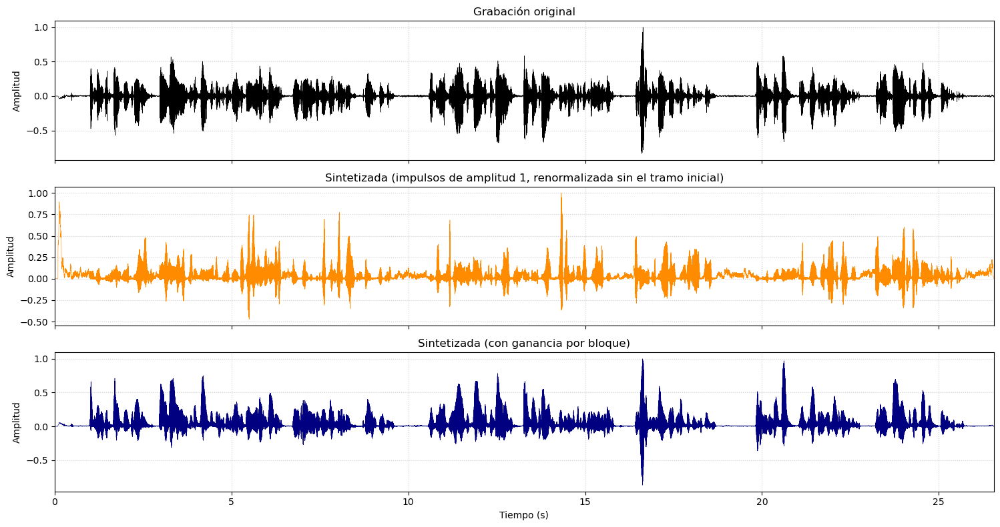

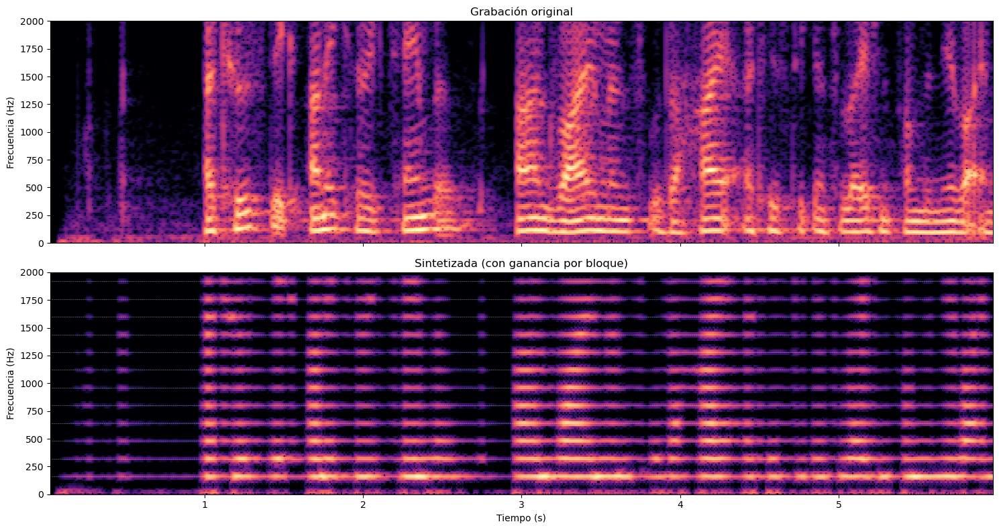

In [22]:
# Comparando en el tiempo y con espectrogramas
t = np.arange(N) / fs

fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
for ax, (titulo, s, color) in zip(axes, [("Grabación original", grab_libre, "black"),
                                         ("Sintetizada (impulsos de amplitud 1, renormalizada sin el tramo inicial)", voz_sint_sin_inicio, "darkorange"),
                                         ("Sintetizada (con ganancia por bloque)", voz_sint_g, "navy")]):
    ax.plot(t, s, color=color, lw=0.4)
    ax.set_title(titulo)
    ax.set_ylabel("Amplitud")
    ax.grid(True, linestyle=":", alpha=0.6)
axes[-1].set_xlabel("Tiempo (s)")
axes[-1].set_xlim(0, t[-1])
plt.tight_layout()
plt.show()

# Espectrogramas de los primeros segundos (zoom 0-2 kHz para ver los armónicos del pitch)
t_max = 6  # s
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, (titulo, s) in zip(axes, [("Grabación original", grab_libre),
                                  ("Sintetizada (con ganancia por bloque)", voz_sint_g)]):
    f_s, t_s, S = spectrogram(s[:t_max * fs], fs=fs, window="hann", nperseg=1024, noverlap=896)
    S_dB = 10 * np.log10(S + 1e-12)
    ax.pcolormesh(t_s, f_s, S_dB, shading="auto", cmap="magma", vmin=S_dB.max() - 70, vmax=S_dB.max())
    if "Sintetizada" in titulo:
        for k in range(1, 13):
            ax.axhline(160 * k, color="white", lw=0.4, ls=":")  # múltiplos de 160 Hz
    ax.set_ylim(0, 2000)
    ax.set_ylabel("Frecuencia (Hz)")
    ax.set_title(titulo)
axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

## ¿Qué ocurre? Discusión

Con la ganancia por bloque la envolvente de amplitud de la señal sintetizada sigue a la de la grabación (las pausas quedan en silencio y las sílabas fuertes son fuertes). Se sigue entendiendo lo que se dice, pero la voz suena como un robot monótono. Esto se explica separando lo que el vocoder conserva y lo que tira:

1. **Lo que se conserva: la envolvente espectral de cada bloque.** Con $M = 12$ (el primer codo del punto 2) el filtro $1/A(z)$ de cada bloque modela solo el tracto vocal, es decir los formantes. Como los formantes son los que distinguen una vocal de otra y cambian con la articulación cada pocas decenas de ms, al actualizarlos cada 25 ms las vocales y la articulación se siguen reconociendo. En el espectrograma se ve que las zonas de energía (formantes) aparecen en los mismos tiempos y frecuencias que en el original.

2. **Lo que se pierde: el pitch y la entonación.** El error de predicción real tenía la información de la fuente: un tren de pulsos con el período propio de la voz, que además cambia todo el tiempo con la entonación. En el espectrograma original se ven los armónicos (separados $f_0$, entre unos 100 y 130 Hz) subiendo y bajando. Al reemplazarlo por un tren fijo de 160 Hz, los armónicos de la señal sintetizada son líneas horizontales exactamente en múltiplos de 160 Hz (líneas punteadas). Toda la entonación desaparece, por eso suena monótona, y como 160 Hz está bastante por encima de la $f_0$ de nuestra voz ($\approx 125$ Hz medida en el punto 2) la voz sintetizada suena más aguda. Además el período es perfectamente constante (sin jitter ni shimmer), lo que la hace sonar todavía más artificial, igual que en el punto 4.

3. **Los sonidos sordos también se excitan con impulsos.** Consonantes como /s/, /sh/, /f/ o /t/ no son sonoras: como vimos en los puntos 2 y 4, su excitación es ruido. Acá todos los bloques reciben el mismo tren de impulsos, así que en vez de un siseo se escucha un zumbido con la envolvente de la consonante. Un vocoder LPC completo decidiría en cada bloque si es sonoro o sordo y usaría ruido en los sordos, y estimaría el período de cada bloque (por ejemplo con la autocorrelación del error, como hicimos en el punto 2) en vez de usar 160 Hz fijo.

4. **La coherencia del tren de impulsos.** Como el tren se genera una sola vez para toda la señal, en la zona donde dos bloques se solapan los impulsos de los dos caen en las mismas posiciones y la suma ponderada por las ventanas (que suman 1) mantiene un único tren de período $P$. Si cada bloque tuviera su propio tren con otra fase, en los solapamientos aparecerían impulsos a destiempo, es decir un pitch irregular y una voz áspera.

5. **El volumen** (la primera versión): como vimos arriba, sin ganancia por bloque un par de bloques casi constantes al principio tienen una ganancia enorme y fijan el pico, y además todos los bloques quedan al mismo nivel sin importar cuán fuerte era el original. Escalando los impulsos con $g_i = \sqrt{J_i \cdot P}$, como en el punto 4, se recupera la información de nivel.